In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.preprocessing import combine_the_data, dict_the_data 

<h3>Importing The Data

In [32]:
#Specific to these scans
path = "scans/data"
scans = []
for x in [19+25,21+25,40+25,42+25,69,70]: scans.append(f"00{x}_0_0")
for x in [20+25,41+25, 68]: scans.append(f"00{x}_mesh") #41 is wrong circle until point 19
for x in [22+25,24+25,26+25,28+25,30+25,32+25,34+25,36+25,38+25]: scans.append(f"00{x}_centre") #34 is wrong circle
for x in [23+25,25+25,27+25,29+25,31+25,33+25,35+25,37+25,39+25]: scans.append(f"00{x}_dmesh") #Scan 29 is wrong circle 
# for x in range(19,39): scans.append(f"000{x}_*")
print(scans)
scans.sort() #need to sort the scans into the order they were taken!!
print(scans)
x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 293 #px #2 values - 292 and 294
start_cy = 254 #px

['0044_0_0', '0046_0_0', '0065_0_0', '0067_0_0', '0069_0_0', '0070_0_0', '0045_mesh', '0066_mesh', '0068_mesh', '0047_centre', '0049_centre', '0051_centre', '0053_centre', '0055_centre', '0057_centre', '0059_centre', '0061_centre', '0063_centre', '0048_dmesh', '0050_dmesh', '0052_dmesh', '0054_dmesh', '0056_dmesh', '0058_dmesh', '0060_dmesh', '0062_dmesh', '0064_dmesh']
['0044_0_0', '0045_mesh', '0046_0_0', '0047_centre', '0048_dmesh', '0049_centre', '0050_dmesh', '0051_centre', '0052_dmesh', '0053_centre', '0054_dmesh', '0055_centre', '0056_dmesh', '0057_centre', '0058_dmesh', '0059_centre', '0060_dmesh', '0061_centre', '0062_dmesh', '0063_centre', '0064_dmesh', '0065_0_0', '0066_mesh', '0067_0_0', '0068_mesh', '0069_0_0', '0070_0_0']


In [33]:
print(scans)
data_concat = combine_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)
print(data_concat.last_valid_index())
print(len(data_concat.dropna()))
display(data_concat.tail(10))

['0044_0_0', '0045_mesh', '0046_0_0', '0047_centre', '0048_dmesh', '0049_centre', '0050_dmesh', '0051_centre', '0052_dmesh', '0053_centre', '0054_dmesh', '0055_centre', '0056_dmesh', '0057_centre', '0058_dmesh', '0059_centre', '0060_dmesh', '0061_centre', '0062_dmesh', '0063_centre', '0064_dmesh', '0065_0_0', '0066_mesh', '0067_0_0', '0068_mesh', '0069_0_0', '0070_0_0']
4137
3968


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
4128,435,924.1278,0.5,1.0,0.499994,1.0,5120,-4777,-343,0.0,...,52.0,6.0,112.0,-88.0,392.0,192.0,-41.0,-202.0,0.372727,1.836364
4129,436,926.1863,0.6,1.0,0.599903,1.0,5120,-5220,100,0.0,...,52.0,6.0,96.0,-88.0,376.0,192.0,-57.0,-202.0,0.518182,1.836364
4130,437,928.2775,0.7,1.0,0.700037,1.0,5120,-5664,544,0.0,...,46.0,6.0,76.0,-94.0,356.0,186.0,-77.0,-208.0,0.700000,1.890909
4131,438,930.3362,0.8,1.0,0.799946,1.0,5120,-6107,987,0.0,...,44.0,6.0,54.0,-96.0,334.0,184.0,-99.0,-210.0,0.900000,1.909091
4132,439,932.4116,0.9,1.0,0.900080,1.0,5120,-6551,1431,0.0,...,44.0,6.0,34.0,-96.0,314.0,184.0,-119.0,-210.0,1.081818,1.909091
4133,440,934.4869,1.0,1.0,0.999989,1.0,5120,-6994,1874,0.0,...,44.0,6.0,16.0,-96.0,296.0,184.0,-137.0,-210.0,1.245455,1.909091
4134,0,20.0254,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,204.0,6.0,194.0,64.0,474.0,344.0,41.0,-50.0,-0.372727,0.454545
4135,1,21.5493,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,204.0,6.0,194.0,64.0,474.0,344.0,41.0,-50.0,-0.372727,0.454545
4136,0,1.2820,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,204.0,6.0,194.0,64.0,474.0,344.0,41.0,-50.0,-0.372727,0.454545
4137,1,2.7739,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,204.0,6.0,194.0,64.0,474.0,344.0,41.0,-50.0,-0.372727,0.454545


In [35]:
print(scans)
all_data = dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)

data_amount = []
data_running_total = 0
for scan in scans: 
    data_amount.append((len(all_data[scan]), len(all_data[scan].dropna())))
    data_running_total = data_running_total + len(all_data[scan].dropna())
    # print(scan, " ", data_running_total)
print(data_amount)

['0044_0_0', '0045_mesh', '0046_0_0', '0047_centre', '0048_dmesh', '0049_centre', '0050_dmesh', '0051_centre', '0052_dmesh', '0053_centre', '0054_dmesh', '0055_centre', '0056_dmesh', '0057_centre', '0058_dmesh', '0059_centre', '0060_dmesh', '0061_centre', '0062_dmesh', '0063_centre', '0064_dmesh', '0065_0_0', '0066_mesh', '0067_0_0', '0068_mesh', '0069_0_0', '0070_0_0']
[(2, 2), (625, 593), (2, 2), (2, 2), (289, 271), (2, 2), (289, 278), (2, 2), (289, 279), (2, 2), (289, 276), (2, 2), (289, 276), (2, 2), (289, 279), (2, 2), (289, 284), (2, 2), (289, 285), (2, 2), (289, 272), (2, 2), (441, 424), (2, 2), (441, 421), (2, 2), (2, 2)]


In [36]:
[(242, 210, 6), (610, 208, 6)]
print(610-242)
print(all_data["0052_dmesh"]["cx"][13])

368
296.0


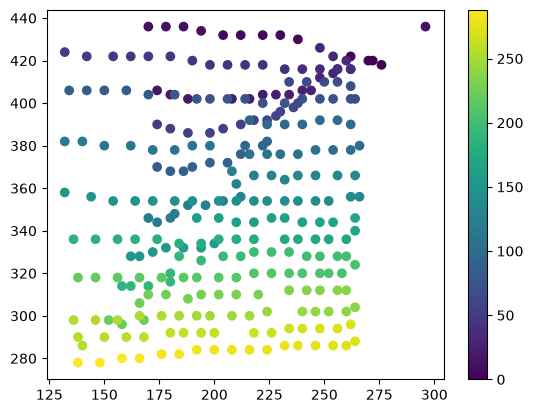

In [37]:
plt.scatter(all_data["0052_dmesh"]["cx"], all_data["0052_dmesh"]["cy"], c=all_data["0052_dmesh"]["point"])
plt.colorbar()

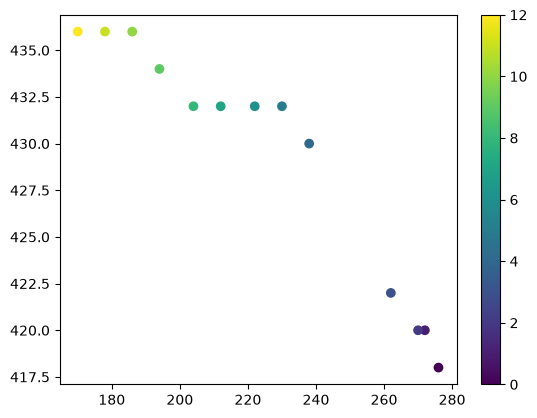

In [ ]:
all_data["0052_dmesh"].loc[13, "cx"] = np.nan #can't work out how to correct it - it's not simply pickd up the wrong circle?
plt.scatter(all_data["0052_dmesh"]["cx"].head(15), all_data["0052_dmesh"]["cy"].head(15), c=all_data["0052_dmesh"]["point"].head(15))
plt.colorbar()

<h3> Saving the data

4137
3967
      point      time    x    y      x_rb  y_rb    s0    s1    s2  strain  \
0         0    1.2729  0.0  0.0  0.000000   0.0     0     0     0     0.0   
1         1    2.7649  0.0  0.0  0.000000   0.0     0     0     0     0.0   
2         0   23.0545  1.2  1.2  1.200032   1.2  6144 -8393  2249     0.0   
3         1   25.1289  1.1  1.2  1.099897   1.2  6144 -7949  1805     0.0   
4         2   27.2035  1.0  1.2  0.999989   1.2  6144 -7506  1362     0.0   
...     ...       ...  ...  ...       ...   ...   ...   ...   ...     ...   
4133    440  934.4869  1.0  1.0  0.999989   1.0  5120 -6994  1874     0.0   
4134      0   20.0254  0.0  0.0  0.000000   0.0     0     0     0     0.0   
4135      1   21.5493  0.0  0.0  0.000000   0.0     0     0     0     0.0   
4136      0    1.2820  0.0  0.0  0.000000   0.0     0     0     0     0.0   
4137      1    2.7739  0.0  0.0  0.000000   0.0     0     0     0     0.0   

      ...  track_cy  track_radius  roi_x_min  roi_y_min  roi_x_ma

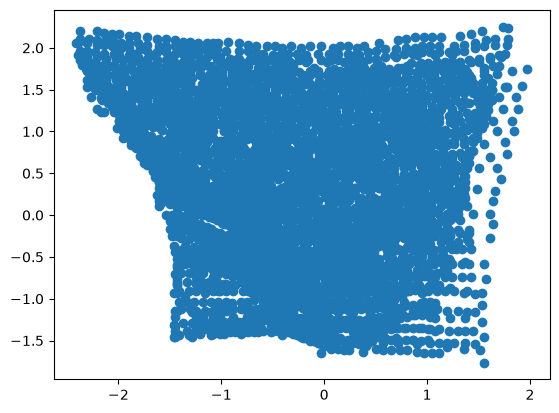

In [45]:
data_concat = pd.concat(all_data,ignore_index=True)
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])
print(data_concat.last_valid_index())
print(len(data_concat.dropna()))
print(data_concat)

In [46]:
data_concat.astype("float32").to_csv("processed_data/27Oct_data.csv")

In [44]:
all_data["0045_mesh"].astype("float32").to_csv("processed_data/27Oct_0045_mesh.csv")

<h3>Plotting The Data

Text(0.5, 1.0, 'set x and y values 27 October')

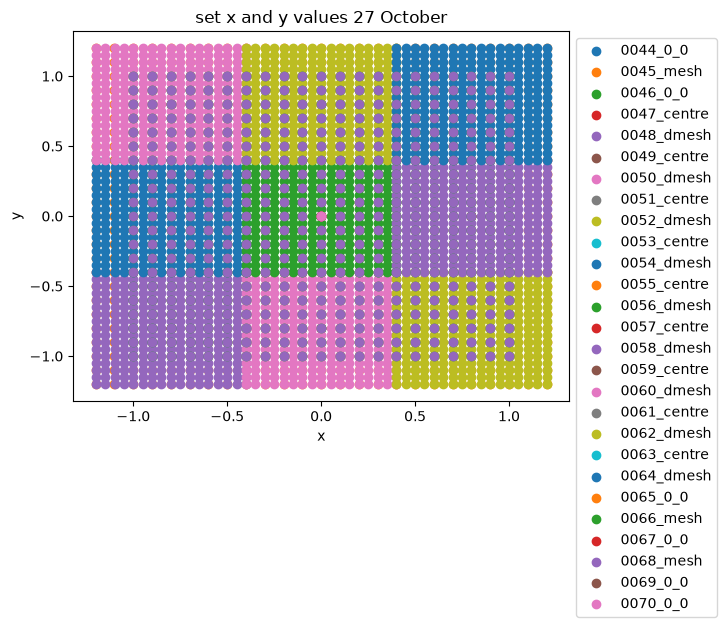

In [8]:
cmap=plt.get_cmap('Paired')
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["x"], all_data[scan]["y"], label=scan) # , color=cmap(i))
plt.ylabel("y")
plt.xlabel("x")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("set x and y values 27 October")

Text(0.5, 1.0, 'measured cx and cy values 27 October')

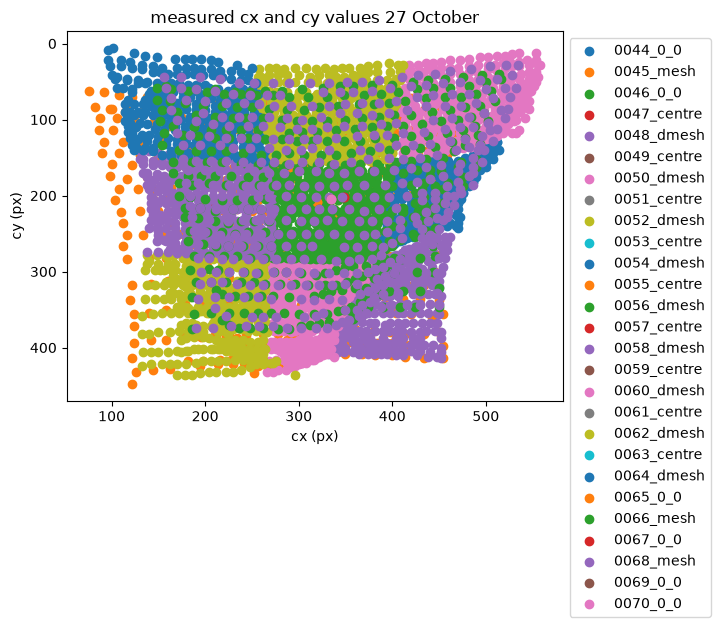

In [9]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, color=cmap(i))
plt.ylabel("cy (px)")
plt.xlabel("cx (px)")
plt.gca().invert_yaxis()
# plt.scatter(382, -270, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("measured cx and cy values 27 October")

Text(0.5, 1.0, 'converted cx and cy values 27 October 2026')

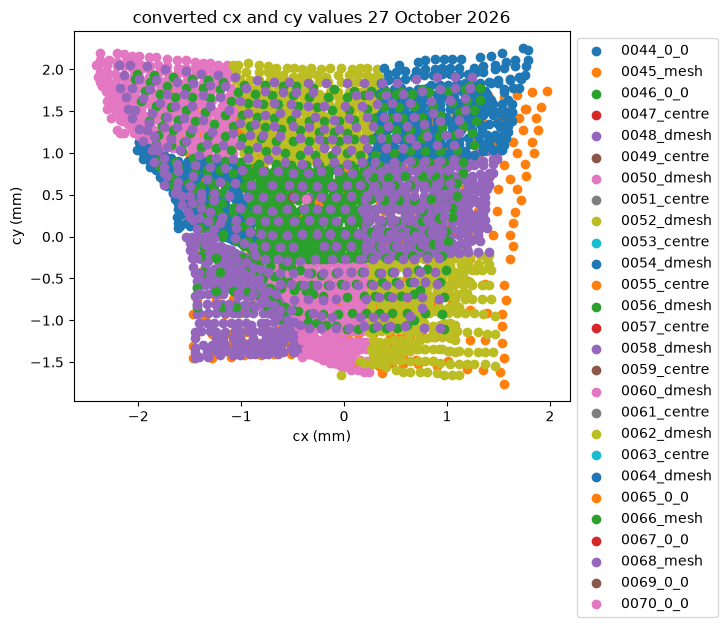

In [10]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx_mm"], all_data[scan]["cy_mm"], label=scan) #, color=cmap(i))
plt.ylabel("cy (mm)")
plt.xlabel("cx (mm)")
# plt.gca().invert_yaxis()
# plt.scatter(382*x_conversion, -270*y_conversion, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("converted cx and cy values 27 October 2026")

In [11]:
#check didn't track the wrong circle at one point by looking at the radius 
for scan in scans: 
    print(scan, "max: ", max(all_data[scan]["radius"].dropna()), "min: ", min(all_data[scan]["radius"].dropna()))
#all 5 or 6 - good 

0044_0_0 max:  6 min:  6
0045_mesh max:  6.0 min:  6.0
0046_0_0 max:  6 min:  6
0047_centre max:  6 min:  6
0048_dmesh max:  6.0 min:  6.0
0049_centre max:  6 min:  6
0050_dmesh max:  6.0 min:  6.0
0051_centre max:  6 min:  6
0052_dmesh max:  6.0 min:  6.0
0053_centre max:  6 min:  6
0054_dmesh max:  6.0 min:  6.0
0055_centre max:  6 min:  6
0056_dmesh max:  6.0 min:  6.0
0057_centre max:  6 min:  6
0058_dmesh max:  6.0 min:  6.0
0059_centre max:  6 min:  6
0060_dmesh max:  6.0 min:  5.0
0061_centre max:  6 min:  6
0062_dmesh max:  6.0 min:  6.0
0063_centre max:  6 min:  6
0064_dmesh max:  6.0 min:  6.0
0065_0_0 max:  6 min:  6
0066_mesh max:  6.0 min:  6.0
0067_0_0 max:  6 min:  6
0068_mesh max:  6.0 min:  6.0
0069_0_0 max:  6 min:  6
0070_0_0 max:  6 min:  6


IndexError: list index out of range

<Figure size 640x480 with 0 Axes>

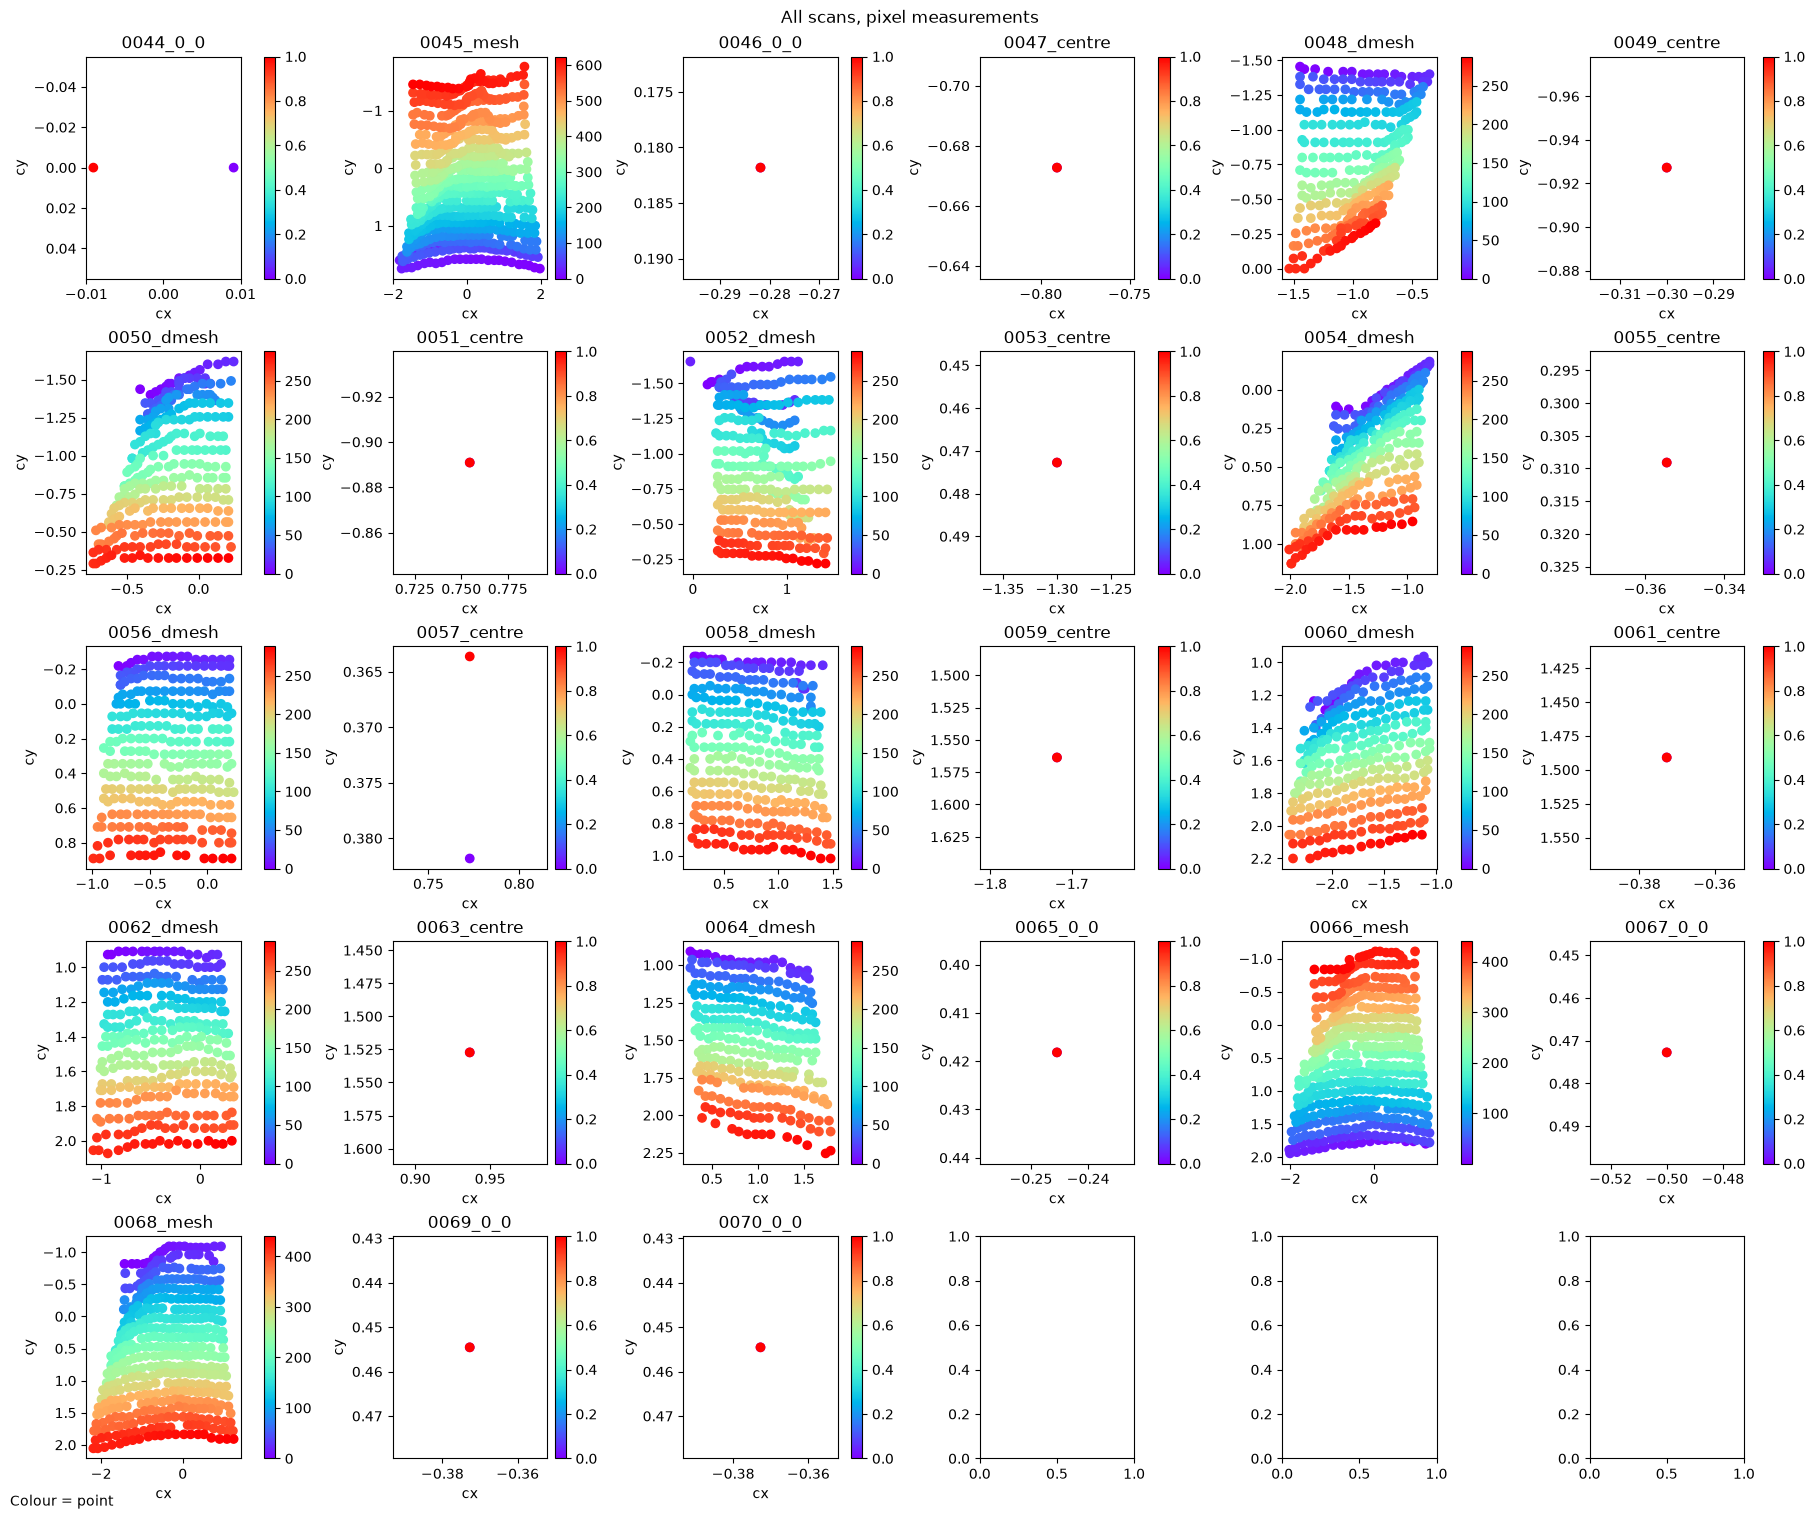

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(5, 6, figsize=(18,15), constrained_layout=True)    

key = 0

fig.suptitle("All scans, pixel measurements")
fig.text(0,0,"Colour = point")


for i in range(5):
    for j in range(6):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans[key]
        # print(dfAtKey)
        im=ax[i,j].scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], label=scan, c=all_data[dfAtKey]["point"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)
        fig.colorbar(im, ax=ax[i,j])
        key += 1

fig.suptitle("All scans, pixel measurements")
fig.text(0,0,"Colour = point")
fig.colorbar(im)

In [ ]:
print(scans)

['0044_0_0', '0045_mesh', '0046_0_0', '0047_centre', '0048_dmesh', '0049_centre', '0050_dmesh', '0051_centre', '0052_dmesh', '0053_centre', '0054_dmesh', '0055_centre', '0056_dmesh', '0057_centre', '0058_dmesh', '0059_centre', '0060_dmesh', '0061_centre', '0062_dmesh', '0063_centre', '0064_dmesh', '0065_0_0', '0066_mesh', '0067_0_0', '0068_mesh', '0069_0_0', '0070_0_0']


Text(0, 0, 'Colour = y')

<Figure size 640x480 with 0 Axes>

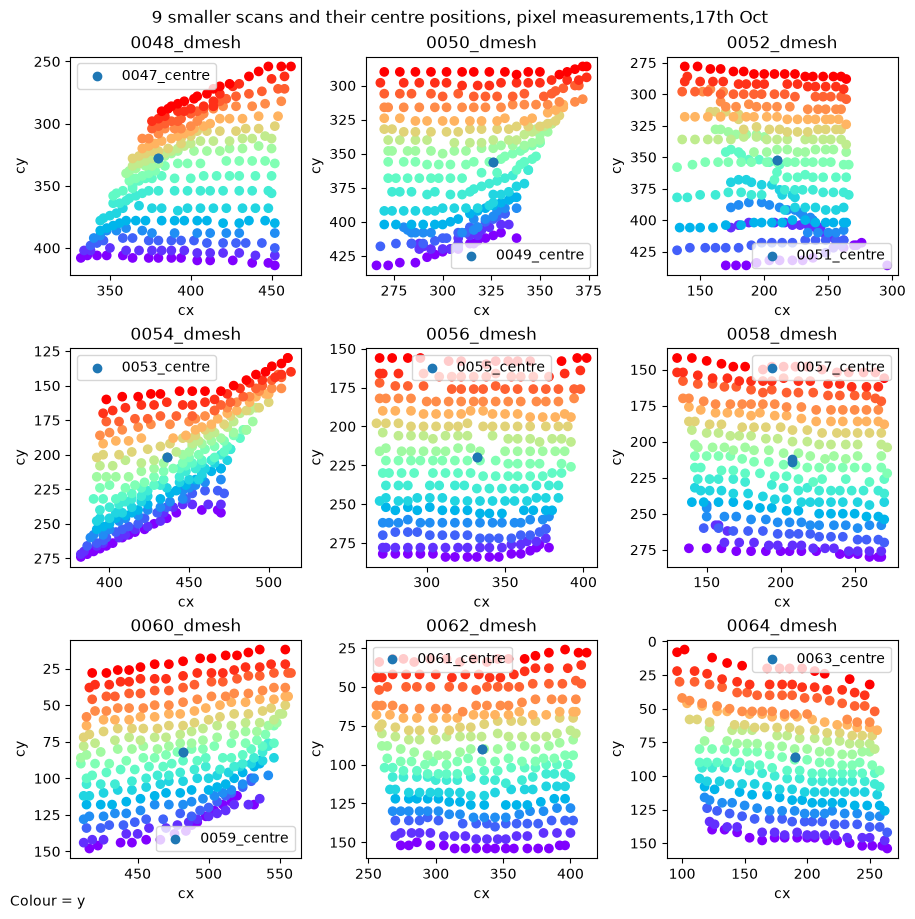

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements,17th Oct")
fig.text(0,0,"Colour = y")

(292.0, 292.0)
(324.0, 324.0)
(320.0, 320.0)
(348.0, 348.0)
[np.int64(292), np.int64(324), np.int64(320), np.int64(348)]
[np.int64(254), np.int64(234), np.int64(208), np.int64(202)]
          2
0.007116 x - 5.445 x + 1236


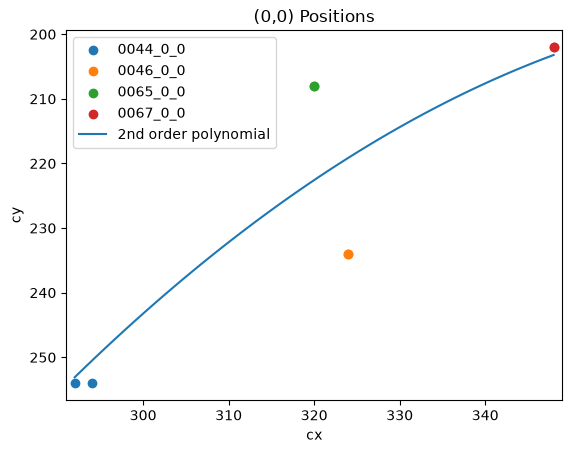

In [ ]:
import math
fig, ax = plt.subplots()    

scans_i = [0,2,21,23]#,24]
scans_to_plot = [scans[i] for i in scans_i]
cx_0_0 = []
cy_0_0 = []

for scan in scans_to_plot:
    ax.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, c=all_data[scan], cmap="rainbow")
    print((float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    ax.annotate(scan, (float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    if math.isnan(all_data[scan]["cx"][0]):
        cx_0_0.append(all_data[scan]["cx"][1])
    else: cx_0_0.append(all_data[scan]["cx"][0])
    if math.isnan(all_data[scan]["cy"][0]):
        cy_0_0.append(all_data[scan]["cy"][1])
    else: cy_0_0.append(all_data[scan]["cy"][0])

ax.yaxis.set_inverted(True)
ax.legend()
ax.set_ylabel("cy")
ax.set_xlabel("cx")
ax.set_title("(0,0) Positions")

print(cx_0_0)
print(cy_0_0)
z = np.polyfit(cx_0_0, cy_0_0, 2)
f = np.poly1d(z)
print(f)
# calculate new x's and y's
x_new = np.linspace(cx_0_0[0], cx_0_0[-1], 50)
y_new = f(x_new)
plt.plot(x_new, y_new, label="2nd order polynomial")
plt.xlim([cx_0_0[0]-1, cx_0_0[-1] + 1 ])
plt.legend()


Text(0, -0.02, 'Colour = y\nScans 28, 29 and 34 tracked the wrong circle')

<Figure size 640x480 with 0 Axes>

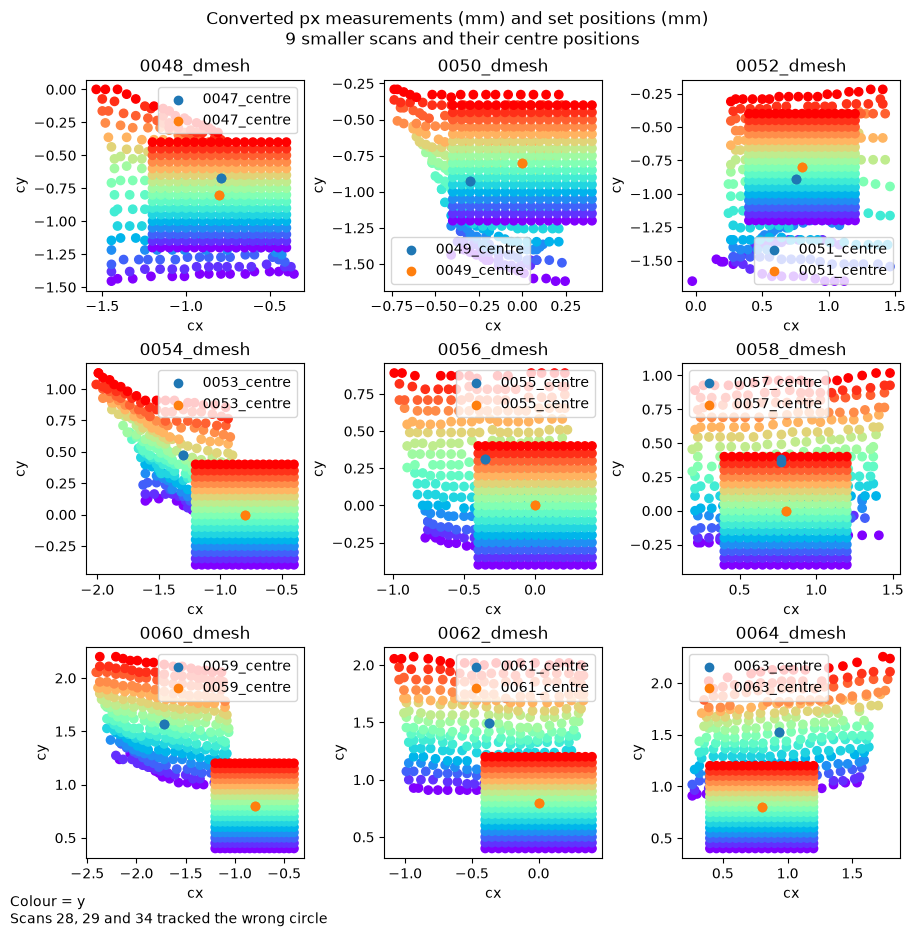

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):scans 28, 29 and 34 tracked the wrong circle"
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]
        

        subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        dfCentre = scans[scans_i[key]-1]
        subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        subplot.legend()

        key += 1
fig.suptitle("Converted px measurements (mm) and set positions (mm) \n 9 smaller scans and their centre positions")
fig.text(0,-0.02,"Colour = y\nScans 28, 29 and 34 tracked the wrong circle")

0048_dmesh 0      0.254545
1      0.236364
2      0.236364
3      0.218182
4           NaN
         ...   
284   -0.145455
285   -0.127273
286   -0.109091
287   -0.090909
288   -0.072727
Length: 289, dtype: float64
0050_dmesh 0      0.236364
1      0.200000
2      0.218182
3      0.236364
4      0.254545
         ...   
284   -0.072727
285   -0.072727
286   -0.072727
287   -0.072727
288   -0.072727
Length: 289, dtype: float64
0052_dmesh 0      0.290909
1      0.309091
2      0.309091
3      0.327273
4      0.400000
         ...   
284   -0.145455
285   -0.163636
286   -0.163636
287   -0.181818
288   -0.181818
Length: 289, dtype: float64
0054_dmesh 0     -0.509091
1     -0.527273
2     -0.527273
3           NaN
4     -0.509091
         ...   
284   -0.490909
285   -0.490909
286   -0.472727
287   -0.472727
288   -0.454545
Length: 289, dtype: float64
0056_dmesh 0     -0.181818
1     -0.200000
2     -0.181818
3     -0.163636
4     -0.145455
         ...   
284         NaN
285   -0.490909
2

Text(0, -0.02, "Colour = difference between measured point and set point\n not sure what's going on with 27")

<Figure size 640x480 with 0 Axes>

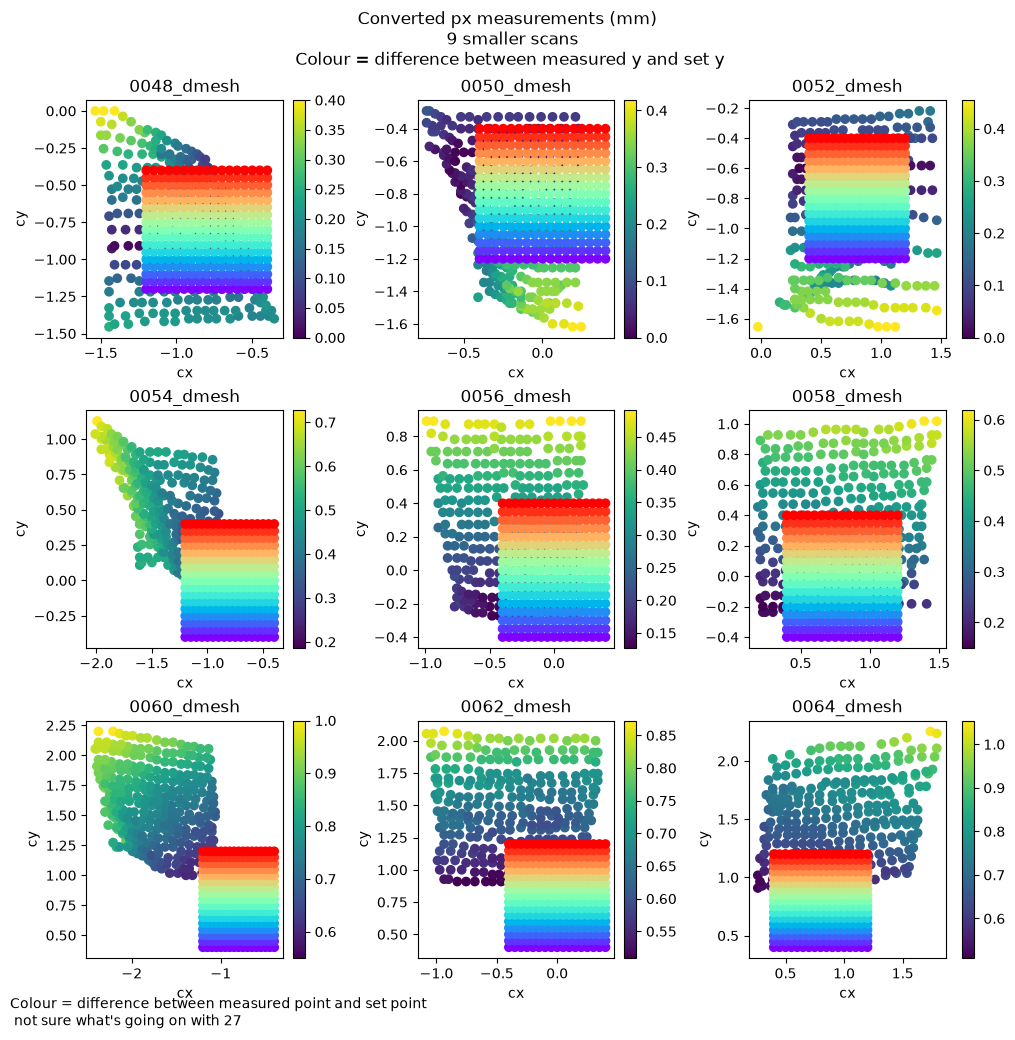

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(10,10),  constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["y"] - all_data[dfAtKey]["cy_mm"]
        print(dfAtKey, difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference), vmin=min(abs(difference)), vmax=max(abs(difference))) #cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        # subplot.legend()
        fig.colorbar(im, ax=subplot)  
        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
# sm =  ScalarMappable(norm=norm, cmap=cmap)
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=axes[:,1])
# cbar.ax.set_title("scale")
fig.suptitle("Converted px measurements (mm) \n 9 smaller scans\nColour = difference between measured y and set y")
fig.text(0,-0.02,"Colour = difference between measured point and set point\n not sure what's going on with 27") #\nScans 28, 29 and 34 tracked the wrong circle

Text(0, -0.02, 'Colour = difference between measured point and set point')

<Figure size 640x480 with 0 Axes>

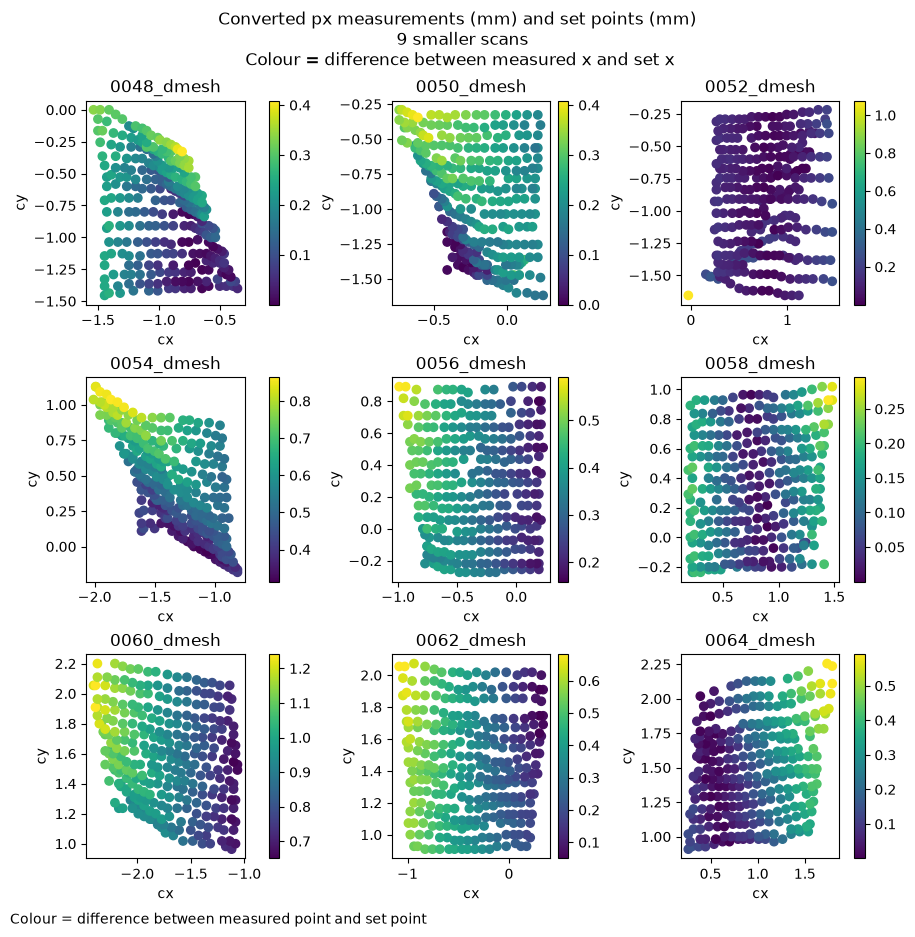

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["x"] - all_data[dfAtKey]["cx_mm"]
        # print(difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference)) #cmap="rainbow") #label=scans_to_plot[key], 
        #subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        fig.colorbar(im, ax=subplot)  
        # subplot.legend()

        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
fig.suptitle("Converted px measurements (mm) and set points (mm) \n 9 smaller scans\nColour = difference between measured x and set x")
fig.text(0,-0.02,"Colour = difference between measured point and set point") #\nScans 28, 29 and 34 tracked the wrong circle")

Text(0.5, 0.98, '9 smaller scans and their centre positions, pixel measurements, 16th Oct')

<Figure size 640x480 with 0 Axes>

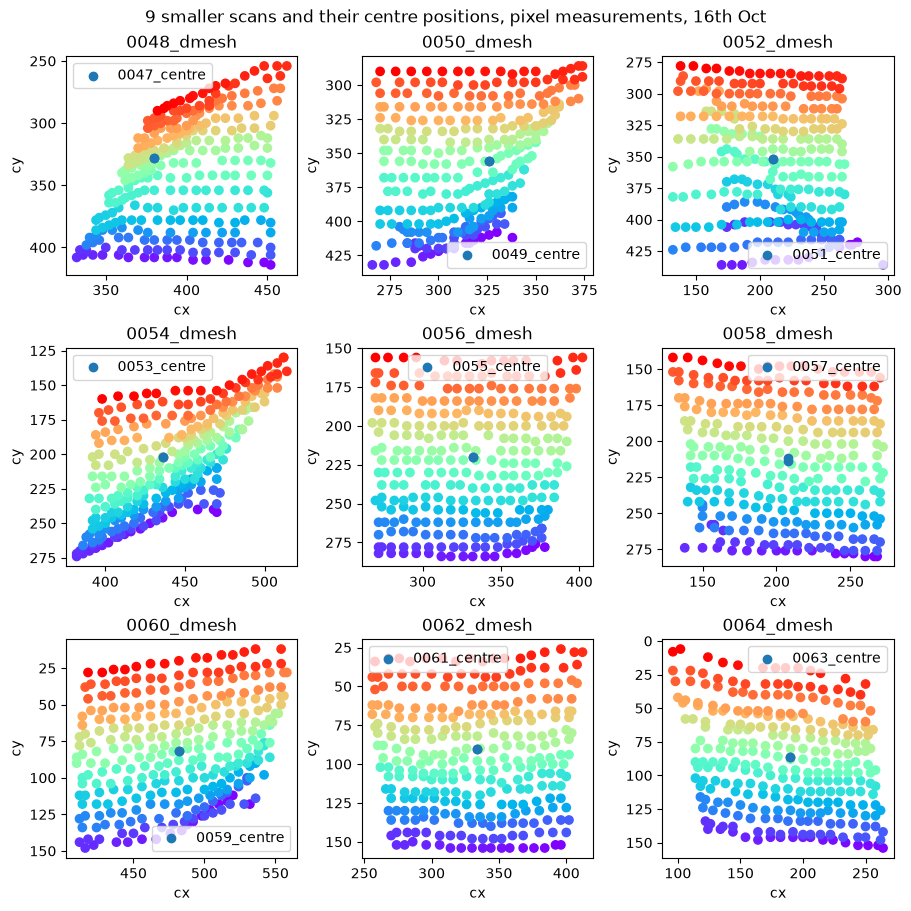

In [ ]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["point"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements, 16th Oct")